# 08: Significant computation part: implementing the algorithms from scratch
**Member 5.** Notebooks 01–07 use scikit-learn. Here every algorithm in the project is re-implemented
using only NumPy (`src/scratch.py`) and checked against scikit-learn on the same data,
split, folds and hyper-parameters. Then we run three
heavier computational experiments: a runtime benchmark, nested cross-validation and a
permutation test.

| Area | Implemented from scratch |
|---|---|
| Protocol | standardisation, stratified K-fold splitter, nested CV, permutation test |
| Linear / probabilistic | logistic regression (accelerated gradient descent), Gaussian Naive Bayes |
| Distance / kernel | KNN (vectorised distances), kernel SVM (SMO dual solver) |
| Trees | CART decision tree, Random Forest with out-of-bag score |
| Dimensionality reduction | PCA (covariance eigendecomposition and power iteration) |
| Feature selection | recursive feature elimination (RFE) |

The scratch classes follow the scikit-learn API, so they run through our common
protocol (`cv_evaluate`, Pipelines) unchanged. The comparison is like for like.

In [1]:
import sys, time
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA
from sklearn.feature_selection import RFE
from sklearn.model_selection import GridSearchCV, cross_val_score, permutation_test_score, StratifiedKFold
from common import *
from scratch import *

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 160, "display.max_columns", 40)
X_train, X_test, y_train, y_test = get_split()
Xtr, Xte, ytr, yte = X_train.values, X_test.values, y_train.values, y_test.values
BP = {k: {p.replace("clf__", ""): v for p, v in d.items()} for k, d in load_best_params().items()}
sc = StandardScaler().fit(Xtr)
A, B = sc.transform(Xtr), sc.transform(Xte)   # scaled train / test for direct comparisons
BP

{'dtree': {'ccp_alpha': 0.0,
  'class_weight': 'balanced',
  'criterion': 'gini',
  'max_depth': 5,
  'min_samples_leaf': 5},
 'dummy': {},
 'gnb': {'var_smoothing': 0.03162277660168379},
 'knn': {'n_neighbors': 3, 'p': 1, 'weights': 'uniform'},
 'lda': {},
 'logreg': {'C': 0.1, 'class_weight': 'balanced', 'l1_ratio': 0},
 'logreg_l1': {'C': 0.31622776601683794,
  'class_weight': 'balanced',
  'l1_ratio': 1},
 'rf': {'class_weight': None,
  'max_depth': None,
  'max_features': 0.5,
  'min_samples_leaf': 2,
  'n_estimators': 200},
 'svm': {'C': 3.1622776601683795,
  'class_weight': 'balanced',
  'gamma': 0.01,
  'kernel': 'rbf'}}

## 1. Standardisation and the stratified K-fold splitter
The scaler learns the mean and standard deviation on the training data only. The splitter
shuffles each class separately and deals its samples to the folds in turn, so every fold
keeps the 37/63 malignant/benign ratio.

In [2]:
diff = np.abs(StandardScalerScratch().fit(Xtr).transform(Xte) - B).max()
print(f"max |scratch scaler - sklearn scaler| on the test set: {diff:.1e}")
rows = []
for name, splits in [("scratch", stratified_kfold_scratch(ytr, 5, seed=RANDOM_STATE)),
                     ("sklearn", get_cv().split(Xtr, ytr))]:
    for k, (tr, te) in enumerate(splits):
        rows.append({"splitter": name, "fold": k + 1, "test size": len(te),
                     "malignant %": round(100 * ytr[te].mean(), 1)})
pd.DataFrame(rows).pivot(index="fold", columns="splitter", values=["test size", "malignant %"])

max |scratch scaler - sklearn scaler| on the test set: 0.0e+00


test size         malignant %        
splitter   scratch sklearn     scratch sklearn
fold                                          
1             91.0    91.0        37.4    37.4
2             91.0    91.0        37.4    37.4
3             91.0    91.0        37.4    37.4
4             91.0    91.0        37.4    37.4
5             91.0    91.0        37.4    37.4

In [3]:
lr_s = Pipeline([("scaler", StandardScalerScratch()),
                 ("clf", LogisticRegressionScratch(C=BP["logreg"]["C"], class_weight=BP["logreg"]["class_weight"]))])
f1_own = cross_val_score(lr_s, Xtr, ytr, cv=list(stratified_kfold_scratch(ytr, 5, RANDOM_STATE)), scoring="f1")
f1_skl = cross_val_score(lr_s, Xtr, ytr, cv=get_cv(), scoring="f1")
print(f"scratch LR, CV F1 with our splitter:     {f1_own.mean():.4f} ± {f1_own.std():.4f}")
print(f"scratch LR, CV F1 with sklearn splitter: {f1_skl.mean():.4f} ± {f1_skl.std():.4f}")

scratch LR, CV F1 with our splitter:     0.9611 ± 0.0156
scratch LR, CV F1 with sklearn splitter: 0.9671 ± 0.0112


Both splitters give perfectly stratified folds. Their CV estimates differ only through
which samples land in which fold. That difference is itself a reminder of how noisy a
single 5-fold estimate is (we quantify this in Section 9).

## 2. Logistic regression and Gaussian Naive Bayes
**Logistic regression.** We minimise the regularised log-loss with gradient descent:

$$J(\beta) = \frac{1}{n}\sum_i w_i\left[\log(1+e^{z_i}) - y_i z_i\right] + \frac{1}{2Cn}\lVert\beta\rVert^2,
\qquad z_i = x_i^\top\beta + \beta_0, \qquad \nabla J = \frac{1}{n}X^\top\big(w\odot(\sigma(z)-y)\big) + \frac{\beta}{Cn}$$

This is scikit-learn's objective divided by $n$, so the same `C` gives the same model.
The step size is $1/L$, where $L$ bounds the gradient's Lipschitz constant. Nesterov
momentum speeds up convergence.

gradient descent converged in 1545 iterations


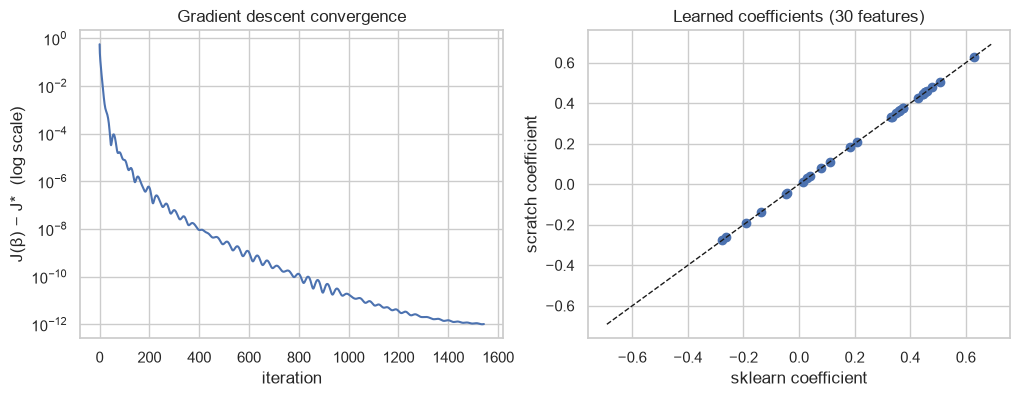

max coefficient difference: 1.7e-06
test-set predictions identical: 100%


In [4]:
p = BP["logreg"]
lr_scr = LogisticRegressionScratch(C=p["C"], class_weight=p["class_weight"]).fit(A, ytr)
lr_skl = LogisticRegression(C=p["C"], class_weight=p["class_weight"], tol=1e-10, max_iter=10000).fit(A, ytr)
print(f"gradient descent converged in {lr_scr.n_iter_} iterations")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
lc = np.array(lr_scr.loss_curve_)
ax[0].semilogy(lc - lc.min() + 1e-12)
ax[0].set_xlabel("iteration"); ax[0].set_ylabel("J(β) − J*  (log scale)")
ax[0].set_title("Gradient descent convergence")
ax[1].scatter(lr_skl.coef_[0], lr_scr.coef_[0])
lim = np.abs(lr_skl.coef_).max() * 1.1
ax[1].plot([-lim, lim], [-lim, lim], "k--", lw=1)
ax[1].set_xlabel("sklearn coefficient"); ax[1].set_ylabel("scratch coefficient")
ax[1].set_title("Learned coefficients (30 features)")
savefig(fig, "08_logreg_scratch"); plt.show()
print(f"max coefficient difference: {np.abs(lr_scr.coef_ - lr_skl.coef_).max():.1e}")
print(f"test-set predictions identical: {np.mean(lr_scr.predict(B) == lr_skl.predict(B)):.0%}")

**Gaussian Naive Bayes.** For each class we estimate a prior and, for each feature, a
mean and a variance. Prediction maximises $\log P(c) + \sum_j \log \mathcal N(x_j;\mu_{cj},\sigma^2_{cj})$.
The log-sum-exp trick keeps the probabilities from underflowing.

In [5]:
gnb_scr = GaussianNBScratch(**BP["gnb"]).fit(A, ytr)
gnb_skl = GaussianNB(**BP["gnb"]).fit(A, ytr)
print(f"max probability difference: {np.abs(gnb_scr.predict_proba(B) - gnb_skl.predict_proba(B)).max():.1e}")

max probability difference: 5.2e-15


## 3. KNN and kernel SVM
**KNN.** The Euclidean distance matrix is one matrix product,
$\lVert a-b\rVert^2 = \lVert a\rVert^2 + \lVert b\rVert^2 - 2a^\top b$. The $k$ nearest
neighbours are found with `argpartition`, which takes $O(n)$ time rather than a full sort.

In [6]:
knn_scr = KNNScratch(**BP["knn"]).fit(A, ytr)
knn_skl = KNeighborsClassifier(**BP["knn"]).fit(A, ytr)
print(f"KNN (k={BP['knn']['n_neighbors']}, p={BP['knn']['p']}) probability difference: "
      f"{np.abs(knn_scr.predict_proba(B) - knn_skl.predict_proba(B)).max():.1e}")

KNN (k=3, p=1) probability difference: 1.1e-16


**SVM via SMO.** We solve the soft-margin dual problem

$$\min_\alpha \tfrac12\alpha^\top Q\alpha - \mathbf 1^\top\alpha \quad\text{s.t.}\quad 0\le\alpha_i\le C_i,\ \ \textstyle\sum_i t_i\alpha_i = 0,
\qquad Q_{ij} = t_i t_j K(x_i,x_j),\ K(x,x') = e^{-\gamma\lVert x-x'\rVert^2}$$

with Sequential Minimal Optimisation, the algorithm inside LIBSVM. Each step picks the
pair $(i,j)$ that most violates the KKT optimality conditions, using second-order
working-set selection, and solves that 2-variable problem exactly. It stops when the
violation gap drops below $10^{-3}$.

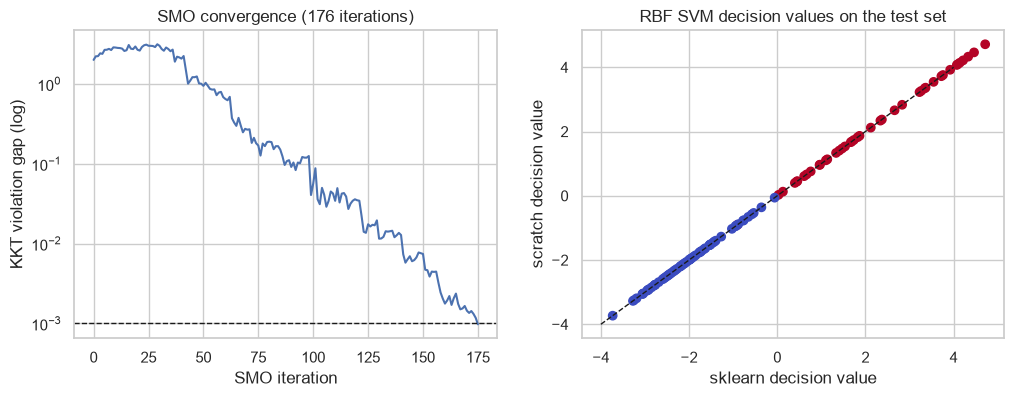

support vectors: scratch 73, sklearn 73
test-set predictions identical: 100%


In [7]:
p = BP["svm"]
svm_scr = SVMScratch(C=p["C"], gamma=p["gamma"], class_weight=p["class_weight"]).fit(A, ytr)
svm_skl = SVC(C=p["C"], gamma=p["gamma"], class_weight=p["class_weight"]).fit(A, ytr)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].semilogy(svm_scr.gap_curve_); ax[0].axhline(1e-3, color="k", ls="--", lw=1)
ax[0].set_xlabel("SMO iteration"); ax[0].set_ylabel("KKT violation gap (log)")
ax[0].set_title(f"SMO convergence ({svm_scr.n_iter_} iterations)")
ax[1].scatter(svm_skl.decision_function(B), svm_scr.decision_function(B), c=yte, cmap="coolwarm")
ax[1].plot([-4, 4], [-4, 4], "k--", lw=1)
ax[1].set_xlabel("sklearn decision value"); ax[1].set_ylabel("scratch decision value")
ax[1].set_title("RBF SVM decision values on the test set")
savefig(fig, "08_svm_smo"); plt.show()
print(f"support vectors: scratch {len(svm_scr.support_)}, sklearn {len(svm_skl.support_)}")
print(f"test-set predictions identical: {np.mean(svm_scr.predict(B) == svm_skl.predict(B)):.0%}")

## 4. CART decision tree and Random Forest
**CART.** At every node, for every feature, we sort the samples once and score all
thresholds in one pass using cumulative class counts. That costs $O(d\,n\log n)$ per node
instead of $O(d\,n^2)$. The split with the largest weighted Gini decrease wins.
Prediction sends all samples down the tree together.

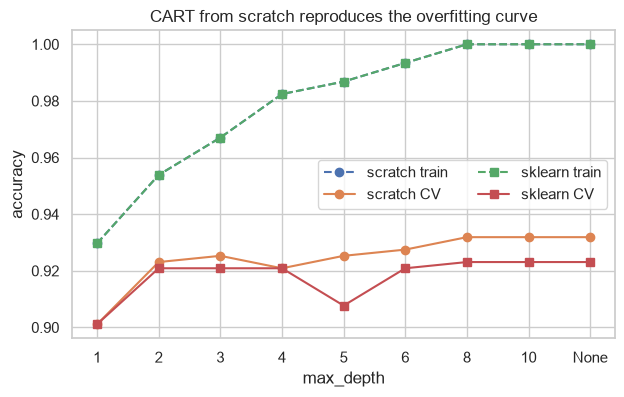

train              cv        
impl      scratch sklearn scratch sklearn
max_depth                                
1           0.930   0.930   0.901   0.901
2           0.954   0.954   0.923   0.921
3           0.967   0.967   0.925   0.921
4           0.982   0.982   0.921   0.921
5           0.987   0.987   0.925   0.908
6           0.993   0.993   0.927   0.921
8           1.000   1.000   0.932   0.923
10          1.000   1.000   0.932   0.923
None        1.000   1.000   0.932   0.923

In [8]:
rows = []
for d in [1, 2, 3, 4, 5, 6, 8, 10, None]:
    for name, est in [("scratch", DecisionTreeScratch(max_depth=d)),
                      ("sklearn", DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE))]:
        cv = cross_val_score(est, Xtr, ytr, cv=get_cv(), scoring="accuracy")
        rows.append({"max_depth": str(d), "impl": name, "train": est.fit(Xtr, ytr).score(Xtr, ytr),
                     "cv": cv.mean()})
dd = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(7, 4))
for (name, g), m in zip(dd.groupby("impl"), ["o", "s"]):
    ax.plot(g["max_depth"], g["train"], m + "--", label=f"{name} train")
    ax.plot(g["max_depth"], g["cv"], m + "-", label=f"{name} CV")
ax.set_xlabel("max_depth"); ax.set_ylabel("accuracy"); ax.legend(ncol=2)
ax.set_title("CART from scratch reproduces the overfitting curve")
savefig(fig, "08_tree_depth_scratch"); plt.show()
order = ["1", "2", "3", "4", "5", "6", "8", "10", "None"]
dd.pivot(index="max_depth", columns="impl", values=["train", "cv"]).loc[order].round(3)

**Random Forest.** Each tree is trained on a bootstrap sample and tries a random subset
of features at every split. The samples a tree never saw (about 37%) give a free
**out-of-bag** estimate of accuracy, with no separate validation set needed.

scratch RF (200 trees) trained in 1.0s, OOB accuracy 0.9604


sklearn RF OOB accuracy 0.9560


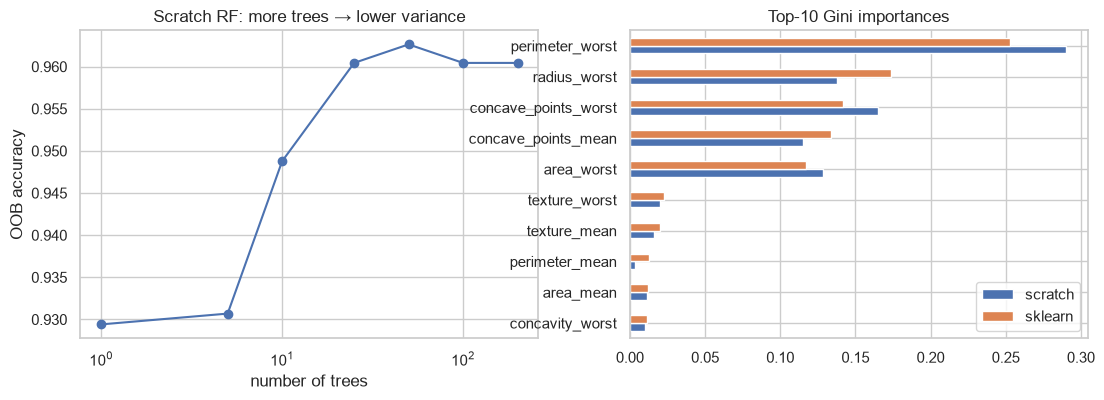

In [9]:
p = BP["rf"]
t0 = time.time()
rf_scr = RandomForestScratch(n_estimators=p["n_estimators"], max_features=p["max_features"],
                             min_samples_leaf=p["min_samples_leaf"], random_state=RANDOM_STATE).fit(Xtr, ytr)
print(f"scratch RF ({p['n_estimators']} trees) trained in {time.time() - t0:.1f}s, OOB accuracy {rf_scr.oob_score_:.4f}")
rf_skl = RandomForestClassifier(**p, oob_score=True, random_state=RANDOM_STATE).fit(Xtr, ytr)
print(f"sklearn RF OOB accuracy {rf_skl.oob_score_:.4f}")

oob = []
for n in [1, 5, 10, 25, 50, 100, 200]:
    m = RandomForestScratch(n_estimators=n, max_features=p["max_features"], min_samples_leaf=p["min_samples_leaf"],
                            random_state=RANDOM_STATE).fit(Xtr, ytr)
    oob.append((n, m.oob_score_))
imp = pd.DataFrame({"scratch": rf_scr.feature_importances_, "sklearn": rf_skl.feature_importances_},
                   index=FEATURE_NAMES).sort_values("sklearn", ascending=False).head(10)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(*zip(*oob), "o-"); ax[0].set_xscale("log")
ax[0].set_xlabel("number of trees"); ax[0].set_ylabel("OOB accuracy")
ax[0].set_title("Scratch RF: more trees → lower variance")
imp[::-1].plot.barh(ax=ax[1]); ax[1].set_title("Top-10 Gini importances")
savefig(fig, "08_rf_scratch"); plt.show()

## 5. PCA from the covariance matrix
PCA = eigendecomposition of the sample covariance $\Sigma = \frac{1}{n-1}X_c^\top X_c$.
The eigenvectors are the principal axes and the eigenvalues are the variance along each.
We implement two solvers: NumPy's exact symmetric eigensolver (`eigh`), and **power
iteration with deflation** written by hand: repeat $v \leftarrow \Sigma v/\lVert\Sigma v\rVert$,
then subtract $\lambda vv^\top$ and find the next component.

In [10]:
pca_skl = PCA(10).fit(A)
pca_eig = PCAScratch(10).fit(A)
pca_pow = PCAScratch(10, solver="power").fit(A)
evr = pd.DataFrame({"sklearn (SVD)": pca_skl.explained_variance_ratio_,
                    "scratch eigh": pca_eig.explained_variance_ratio_,
                    "scratch power": pca_pow.explained_variance_ratio_,
                    "power iterations": pca_pow.power_iters_}, index=[f"PC{i+1}" for i in range(10)])
lam = PCAScratch().fit(A).explained_variance_
evr["eigengap λ(k+1)/λ(k)"] = lam[1:11] / lam[:10]
print(f"max |component| difference vs sklearn: eigh {np.abs(np.abs(pca_eig.components_) - np.abs(pca_skl.components_)).max():.1e}, "
      f"power {np.abs(np.abs(pca_pow.components_) - np.abs(pca_skl.components_)).max():.1e}")
print("components for 95% variance:", PCAScratch(0.95).fit(A).n_components_)
evr.round(4)

max |component| difference vs sklearn: eigh 5.7e-15, power 5.3e-06
components for 95% variance: 10


,sklearn (SVD),scratch eigh,scratch power,power iterations,eigengap λ(k+1)/λ(k)
PC1,0.4459,0.4459,0.4459,18,0.4159
PC2,0.1855,0.1855,0.1855,24,0.5168
PC3,0.0958,0.0958,0.0958,37,0.6880
PC4,0.0659,0.0659,0.0659,50,0.8527
PC5,0.0562,0.0562,0.0562,41,0.7094
PC6,0.0399,0.0399,0.0399,25,0.5552
PC7,0.0221,0.0221,0.0221,40,0.7288
PC8,0.0161,0.0161,0.0161,58,0.7960
PC9,0.0128,0.0128,0.0128,123,0.9073
PC10,0.0117,0.0117,0.0117,88,0.8651


Power iteration converges at a rate set by the ratio $\lambda_{k+1}/\lambda_k$. When two
eigenvalues are close (ratio near 1), it needs many more iterations, as the table shows.

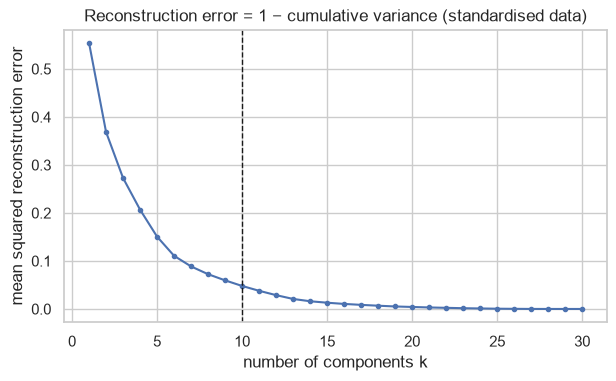

In [11]:
ks = range(1, 31)
err = [np.mean((A - PCAScratch(k).fit(A).inverse_transform(PCAScratch(k).fit(A).transform(A))) ** 2) for k in ks]
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(ks, err, "o-", ms=3); ax.axvline(10, color="k", ls="--", lw=1)
ax.set_xlabel("number of components k"); ax.set_ylabel("mean squared reconstruction error")
ax.set_title("Reconstruction error = 1 − cumulative variance (standardised data)")
savefig(fig, "08_pca_reconstruction"); plt.show()

## 6. Recursive feature elimination
Fit logistic regression, drop the feature with the smallest |coefficient|, refit, and
repeat until $k$ features remain. Our RFE uses our own logistic regression inside.

In [12]:
rfe_scr = RFEScratch(LogisticRegressionScratch(C=1.0), n_features_to_select=5).fit(Xtr, ytr)
rfe_skl = RFE(LogisticRegression(C=1.0, max_iter=5000), n_features_to_select=5).fit(A, ytr)
print("scratch RFE keeps:", [FEATURE_NAMES[i] for i in np.flatnonzero(rfe_scr.support_)])
print("sklearn RFE keeps:", [FEATURE_NAMES[i] for i in np.flatnonzero(rfe_skl.support_)])
rank = pd.DataFrame({"scratch": rfe_scr.ranking_, "sklearn rank (1 = kept)": rfe_skl.ranking_}, index=FEATURE_NAMES)
print(f"Spearman correlation of elimination order: {rank.corr(method='spearman').iloc[0, 1]:.3f}")

rows = []
for k in [5, 10, 15]:
    pipe = Pipeline([("rfe", RFEScratch(LogisticRegressionScratch(C=1.0), k)),
                     ("scaler", StandardScalerScratch()),
                     ("clf", LogisticRegressionScratch(C=BP["logreg"]["C"], class_weight="balanced"))])
    rows.append(cv_evaluate(pipe, Xtr, ytr, name="scratch RFE → scratch LR", k=k))
summarize(rows)[["model", "k", "accuracy", "recall", "f1"]]

scratch RFE keeps: ['radius_se', 'radius_worst', 'texture_worst', 'area_worst', 'concave_points_worst']
sklearn RFE keeps: ['radius_se', 'radius_worst', 'texture_worst', 'area_worst', 'concave_points_worst']
Spearman correlation of elimination order: 0.992


,model,k,accuracy,recall,f1
0,scratch RFE → scratch LR,5,0.9626 ± 0.0088,0.9412 ± 0.0322,0.9493 ± 0.0131
1,scratch RFE → scratch LR,10,0.9670 ± 0.0120,0.9353 ± 0.0432,0.9546 ± 0.0175
2,scratch RFE → scratch LR,15,0.9714 ± 0.0112,0.9471 ± 0.0343,0.9611 ± 0.0158


Selection happens inside each CV fold, as part of the pipeline, so there is no leakage.
A fully hand-written pipeline (RFE, scaler, classifier) with 5 features reaches roughly
the same CV F1 as notebook 06's scikit-learn version.

## 7. Head-to-head: every scratch model vs scikit-learn
Same tuned hyper-parameters (from `best_params.json`), same 5 folds, same metrics. We
also report how often the two implementations give the same prediction on the held-out
test set. Nothing is tuned here, so looking at the test set is safe.

In [13]:
def pair(key):
    p = BP[key]
    if key == "logreg":
        return (LogisticRegressionScratch(C=p["C"], class_weight=p["class_weight"]),
                LogisticRegression(C=p["C"], class_weight=p["class_weight"], max_iter=10000), True)
    if key == "gnb":
        return GaussianNBScratch(**p), GaussianNB(**p), True
    if key == "knn":
        return KNNScratch(**p), KNeighborsClassifier(**p), True
    if key == "svm":
        return (SVMScratch(C=p["C"], gamma=p["gamma"], class_weight=p["class_weight"]),
                SVC(C=p["C"], gamma=p["gamma"], class_weight=p["class_weight"]), True)
    if key == "dtree":
        q = {k: v for k, v in p.items() if k != "ccp_alpha"}
        return DecisionTreeScratch(**q), DecisionTreeClassifier(**q, random_state=RANDOM_STATE), False
    if key == "rf":
        q = dict(n_estimators=p["n_estimators"], max_features=p["max_features"],
                 min_samples_leaf=p["min_samples_leaf"], max_depth=p["max_depth"], class_weight=p["class_weight"])
        return RandomForestScratch(**q, random_state=RANDOM_STATE), RandomForestClassifier(**q, random_state=RANDOM_STATE), False

rows, agree = [], {}
for key in ["logreg", "gnb", "knn", "svm", "dtree", "rf"]:
    scr, skl, scale = pair(key)
    pipes = {"scratch": Pipeline(([("scaler", StandardScalerScratch())] if scale else []) + [("clf", scr)]),
             "sklearn": Pipeline(([("scaler", StandardScaler())] if scale else []) + [("clf", skl)])}
    for impl, pipe in pipes.items():
        rows.append(cv_evaluate(pipe, Xtr, ytr, name=key, impl=impl))
    preds = [pp.fit(Xtr, ytr).predict(Xte) for pp in pipes.values()]
    agree[key] = np.mean(preds[0] == preds[1])
h2h = pd.DataFrame(rows)
h2h["model"] = h2h["model"].map({"logreg": "Logistic Regression", "gnb": "Gaussian NB", "knn": "KNN",
                                 "svm": "SVM (RBF)", "dtree": "Decision Tree", "rf": "Random Forest"})
save_rows(rows, "cv_08_scratch_vs_sklearn.csv")
tbl = h2h.pivot(index="model", columns="impl", values="cv_f1").round(4)
tbl["|Δ F1|"] = (tbl["scratch"] - tbl["sklearn"]).abs().round(4)
tbl["test predictions identical"] = [f"{agree[k]:.1%}" for k in
                                     tbl.index.map({"Logistic Regression": "logreg", "Gaussian NB": "gnb", "KNN": "knn",
                                                    "SVM (RBF)": "svm", "Decision Tree": "dtree", "Random Forest": "rf"})]
tbl

impl,scratch,sklearn,|Δ F1|,test predictions identical
model,,,,
Decision Tree,0.9274,0.9378,0.0104,99.1%
Gaussian NB,0.9214,0.9214,0.0000,100.0%
KNN,0.9667,0.9667,0.0000,100.0%
Logistic Regression,0.9671,0.9671,0.0000,100.0%
Random Forest,0.9519,0.9587,0.0068,100.0%
SVM (RBF),0.9760,0.9760,0.0000,100.0%


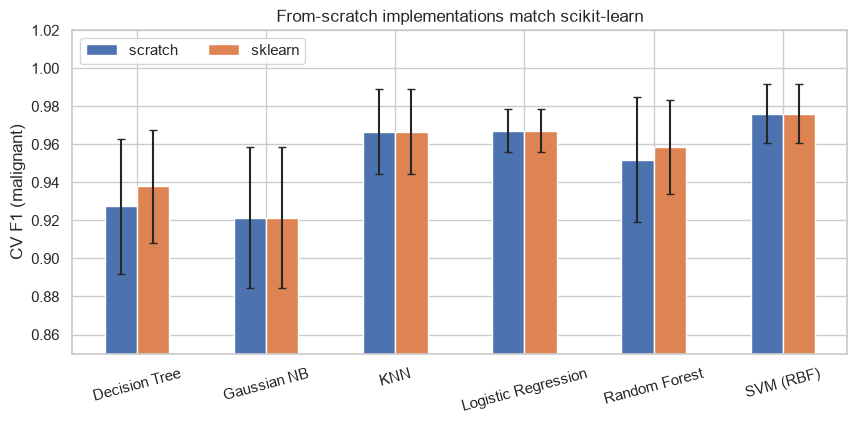

In [14]:
fig, ax = plt.subplots(figsize=(10, 4.2))
pv = h2h.pivot(index="model", columns="impl", values="cv_f1")
er = h2h.pivot(index="model", columns="impl", values="cv_f1_std")
pv.plot.bar(yerr=er, ax=ax, capsize=3, rot=15)
ax.set_ylim(0.85, 1.02); ax.set_ylabel("CV F1 (malignant)"); ax.set_xlabel("")
ax.legend(ncol=2, loc="upper left")
ax.set_title("From-scratch implementations match scikit-learn")
savefig(fig, "08_scratch_vs_sklearn"); plt.show()

The deterministic algorithms (LR, GNB, KNN, SVM) match scikit-learn to numerical
precision: the same F1 to four decimals and identical test predictions. The trees differ
slightly because there are ties. When two splits are equally good, scikit-learn breaks the
tie with a random feature order and we take the first one. Random Forests also use
different random numbers. The gaps (0.010 F1 for the tree, 0.007 for the forest) are well
inside the fold-to-fold standard deviation (0.03), and the test predictions agree on 99–100%.

## 8. Runtime benchmark
Median fit + predict time over 5 runs on the 455-sample training set, then how the cost
grows with the number of training samples $n$.

In [15]:
def timeit(est, Xa, Xb, y, reps=5):
    ts = []
    for _ in range(reps):
        t = time.perf_counter(); est.fit(Xa, y); est.predict(Xb); ts.append(time.perf_counter() - t)
    return np.median(ts) * 1000

rows = []
for key in ["logreg", "gnb", "knn", "svm", "dtree", "rf"]:
    scr, skl, scale = pair(key)
    Xa, Xb = (A, B) if scale else (Xtr, Xte)
    reps = 2 if key == "rf" else 5
    rows.append({"model": key, "scratch ms": timeit(scr, Xa, Xb, ytr, reps), "sklearn ms": timeit(skl, Xa, Xb, ytr, reps)})
rt = pd.DataFrame(rows)
rt["slowdown ×"] = rt["scratch ms"] / rt["sklearn ms"]
save_rows(rt.to_dict("records"), "runtime_08.csv")
rt.round(2)

,model,scratch ms,sklearn ms,slowdown ×
0,logreg,72.99,4.29,17.03
1,gnb,0.37,0.86,0.43
2,knn,8.14,2.60,3.13
3,svm,13.46,4.30,3.13
4,dtree,23.18,6.28,3.69
5,rf,1220.98,273.62,4.46


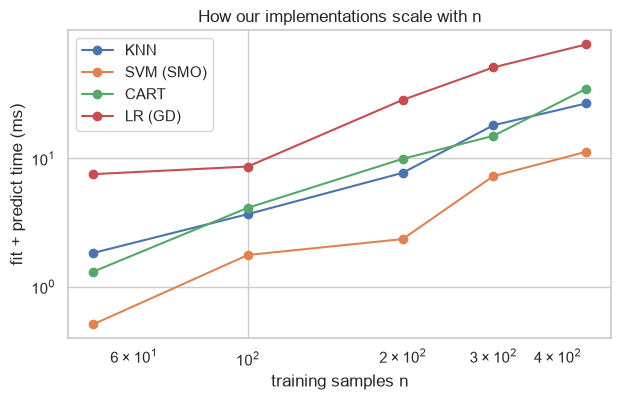

KNN          1.25
SVM (SMO)    1.36
CART         1.42
LR (GD)      1.15
Name: empirical exponent (time ∝ n^a), dtype: float64

In [16]:
sizes = [50, 100, 200, 300, 455]
curves = {k: [] for k in ["KNN", "SVM (SMO)", "CART", "LR (GD)"]}
rng = np.random.default_rng(RANDOM_STATE)
for n in sizes:
    idx = np.sort(rng.choice(len(ytr), n, replace=False)) if n < len(ytr) else np.arange(len(ytr))
    curves["KNN"].append(timeit(KNNScratch(3, p=1), A[idx], A, ytr[idx], 3))
    curves["SVM (SMO)"].append(timeit(SVMScratch(**{k: BP["svm"][k] for k in ["C", "gamma", "class_weight"]}), A[idx], B, ytr[idx], 3))
    curves["CART"].append(timeit(DecisionTreeScratch(), Xtr[idx], Xte, ytr[idx], 3))
    curves["LR (GD)"].append(timeit(LogisticRegressionScratch(C=0.1, class_weight="balanced"), A[idx], B, ytr[idx], 3))
fig, ax = plt.subplots(figsize=(7, 4))
for k, v in curves.items():
    ax.loglog(sizes, v, "o-", label=k)
ax.set_xlabel("training samples n"); ax.set_ylabel("fit + predict time (ms)")
ax.set_title("How our implementations scale with n"); ax.legend()
savefig(fig, "08_runtime_scaling"); plt.show()
slopes = {k: np.polyfit(np.log(sizes), np.log(v), 1)[0] for k, v in curves.items()}
pd.Series(slopes, name="empirical exponent (time ∝ n^a)").round(2)

On the log–log plot, the slope is the empirical complexity exponent. In theory KNN
prediction is $O(n)$ per query, the SVM kernel matrix is $O(n^2)$ and CART is
$O(d\,n\log n)$ per tree level. At our small sizes ($n \le 455$) fixed per-iteration
Python overhead dominates, so all the measured exponents are around 1.1–1.4. The
quadratic kernel cost would only show at much larger $n$.

Most of our NumPy implementations are within 2–4× of scikit-learn's compiled C/Cython
code. Our Gaussian NB is even faster because it skips input validation. The exception is
logistic regression (about 20× slower): first-order gradient descent needs about 1,500
iterations, while scikit-learn's solver uses curvature information and converges in a
handful of steps. That is a good illustration of why optimisers matter.

## 9. Nested cross-validation: is our tuned CV score optimistic?
In notebooks 02–04 the hyper-parameters were chosen to maximise the 5-fold CV F1, and we
reported that same maximum. Choosing the best of many candidates biases that number
upwards. **Nested CV** removes the bias. An inner 5-fold grid search tunes the model
using only the outer-training part of each of 5 outer folds, and the tuned model is then
scored on the outer-test fold it never saw. For the RBF SVM that is
5 outer × 184 candidates × 5 inner = **4,600 model fits**, plus refits (over 10,000 across the four models).

In [17]:
from models import build_pipeline, GRIDS
rows = []
for key in ["logreg", "knn", "svm", "rf"]:
    outer = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE + 1)
    t = time.time()
    inner = GridSearchCV(build_pipeline(key), GRIDS[key], cv=get_cv(), scoring="f1", n_jobs=-1)
    nested = cross_val_score(inner, Xtr, ytr, cv=outer, scoring="f1")
    flat = tune(build_pipeline(key), GRIDS[key], Xtr, ytr).best_score_
    rows.append({"model": key, "non-nested (best grid CV F1)": flat, "nested CV F1": nested.mean(),
                 "nested std": nested.std(), "optimism": flat - nested.mean(), "seconds": time.time() - t})
nest = pd.DataFrame(rows)
save_rows(rows, "nested_cv_08.csv")
nest.round(4)

/opt/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.

/opt/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.

/opt/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.

,model,non-nested (best grid CV F1),nested CV F1,nested std,optimism,seconds
0,logreg,0.9674,0.9548,0.0172,0.0126,130.5519
1,knn,0.9667,0.9453,0.0324,0.0214,2.4363
2,svm,0.9760,0.9553,0.0189,0.0207,11.3355
3,rf,0.9587,0.9368,0.0402,0.0219,372.9590


The optimism column shows how much the "best grid score" overstates performance on unseen
data: about 0.01–0.02 F1 for every model. That is roughly the size of one fold's standard
deviation, so it is worth reporting honestly. It does not change the conclusions: the RBF
SVM and logistic regression stay on top (nested F1 about 0.955) and Random Forest stays
below them. This is also why notebook 07 judges the final models on the untouched test set.

## 10. Permutation test: is the model learning anything real?
We shuffle the labels 1,000 times, re-run the full 5-fold CV of our **from-scratch**
logistic regression each time, and see where the real score falls in that "no signal"
distribution. That is 5,000 model fits.

86s; real CV F1 = 0.9671; permuted mean = 0.4163 ± 0.0355; max permuted = 0.5169; p-value = 0.0010


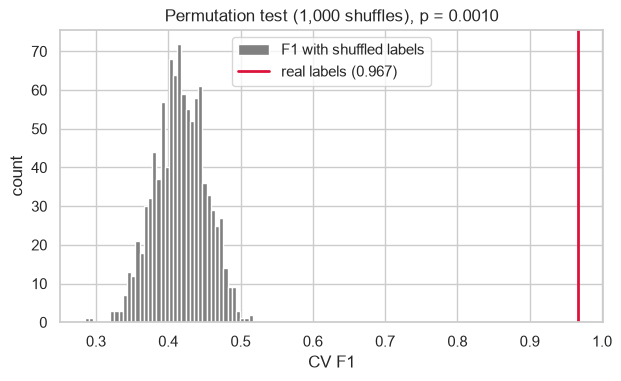

In [18]:
t = time.time()
pipe = Pipeline([("scaler", StandardScalerScratch()),
                 ("clf", LogisticRegressionScratch(C=BP["logreg"]["C"], class_weight="balanced", max_iter=2000))])
score, perm, pval = permutation_test_score(pipe, Xtr, ytr, cv=get_cv(), scoring="f1",
                                           n_permutations=1000, random_state=RANDOM_STATE, n_jobs=-1)
print(f"{time.time() - t:.0f}s; real CV F1 = {score:.4f}; permuted mean = {perm.mean():.4f} ± {perm.std():.4f}; "
      f"max permuted = {perm.max():.4f}; p-value = {pval:.4f}")
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.hist(perm, bins=40, color="grey", label="F1 with shuffled labels")
ax.axvline(score, color="crimson", lw=2, label=f"real labels ({score:.3f})")
ax.set_xlabel("CV F1"); ax.set_ylabel("count"); ax.legend()
ax.set_title(f"Permutation test (1,000 shuffles), p = {pval:.4f}")
savefig(fig, "08_permutation_test"); plt.show()

With shuffled labels, F1 is about 0.42 (chance level for a balanced classifier). Our real score is far beyond every
permuted score, so p = 1/1001, the smallest value 1,000 permutations can give. The
relationship between the measurements and the diagnosis is real and not an artefact of
the CV procedure.

## Summary
* Every algorithm in the project was implemented in NumPy and plugs into the same pipeline.
* The deterministic models reproduce scikit-learn exactly: coefficients and probabilities
  to $10^{-6}$ or better, SVM decision values to the SMO stopping tolerance, and the same CV
  F1 and test predictions. The trees and forests agree within CV noise.
* Convergence analyses: GD loss curve, SMO KKT gap, power-iteration speed vs eigengap,
  and OOB accuracy vs number of trees.
* Heavier experiments: a runtime/complexity benchmark, nested CV (over 10k fits across
  the four models) showing that tuning optimism is about 0.01–0.02 F1, and a permutation test
  (5k fits) with p ≈ 0.001.